<a href="https://colab.research.google.com/github/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/blob/main/Equipo_04_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 3: Analítica Predictiva

Programación para Analítica Descriptiva y Predictiva · Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

| Campo | Datos del equipo |
|---|---|
| Equipo (04) | |
| Integrantes | 271770 – Gerardo Isidoro Reyes <br/> 271760 – Juan Carlos Rivera Cordova <br/> 271758 – Kevin Angel Quiñonez Dominguez |
| Conjunto de datos | EngineFaultDB: A Novel Dataset for Automotive Engine Fault Classification and Baseline Results |
| Fuente o enlace de descarga | https://github.com/leoxthomas/EngineFaultDB |
| Fecha | 2026-11-12 |

**Indicaciones**

- Complete cada sección debajo de su encabezado: el texto en celdas Markdown y el código en celdas de código.
- Mantenga el orden de las secciones. Puede agregar las celdas que necesite dentro de cada una.
- Cada decisión se justifica con texto en Markdown.
- El notebook debe ejecutarse de principio a fin sin errores (Restart and run all).
- Nombre del archivo a entregar: `Equipo_NN_Notebook.ipynb`.

## Preparación del entorno y carga de datos

Importaciones, semilla global y carga del conjunto de datos.

In [1]:
%pip install -q --upgrade fg-data-profiling ipywidgets setuptools

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
#from ydata_profiling import ProfileReport
from ydata_profiling import ProfileReport
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

seed = 42

In [18]:
# Carga de dataset
url = 'https://raw.githubusercontent.com/leoxthomas/EngineFaultDB/refs/heads/main/EngineFaultDB_Final.csv'
df_original = pd.read_csv(url)
df = df_original.copy()
display(df_original)

,Fault,MAP,TPS,Force,Power,RPM,Consumption L/H,Consumption L/100KM,Speed,CO,HC,CO2,O2,Lambda,AFR
0,0,3.549,1.889,7.428,5.227,1192.769,3.057,11.720,24.901,0.460,196.089,14.356,1.080,1.047,15.385
1,0,3.559,1.899,7.646,5.327,1145.191,2.914,11.276,25.030,0.478,196.283,14.492,1.107,1.083,15.926
2,0,3.539,1.899,7.578,5.100,1208.505,2.976,11.926,24.213,0.464,200.367,14.443,1.099,1.072,15.754
3,0,3.519,1.889,7.371,5.255,1164.127,2.908,11.786,24.407,0.471,195.345,13.853,1.076,1.006,14.787
4,0,3.549,1.879,7.405,5.177,1172.032,2.898,12.169,24.875,0.468,194.979,13.752,1.060,0.984,14.470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55994,3,1.971,1.278,92.665,3.589,4584.034,5.423,5.623,95.090,0.902,162.065,13.123,0.568,0.966,14.200
55995,3,1.879,1.258,96.644,3.579,4662.496,5.655,5.578,100.032,0.926,161.237,13.591,0.585,1.030,15.147
55996,3,1.960,1.288,93.961,3.493,4792.675,5.542,5.572,98.595,0.925,160.030,12.999,0.579,0.974,14.324
55997,3,1.930,1.299,95.379,3.618,4563.732,5.525,5.568,98.575,0.942,159.800,13.187,0.579,0.990,14.550


## Sección 1. Problema predictivo

**Debe incluir:**

- Variable objetivo.
- Tipo de problema (clasificación o regresión).
- Métrica principal y su justificación según el costo de los errores.

In [19]:
print('Filas y columnas:', df.shape)
print('Filas duplicadas:', df.duplicated().sum())
print()
display(df.info())

print()
display(df.describe())
print()

# Verificar las clases exactas de la variable objetivo y su proporción
print("Conteo por clase en 'Fault':")
print(df['Fault'].value_counts())

print("\nPorcentaje por clase (%):")
print((df['Fault'].value_counts(normalize=True) * 100).round(2))



Filas y columnas: (55999, 15)
Filas duplicadas: 1

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55999 entries, 0 to 55998
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Fault                55999 non-null  int64  
 1   MAP                  55999 non-null  float64
 2   TPS                  55999 non-null  float64
 3   Force                55999 non-null  float64
 4   Power                55999 non-null  float64
 5   RPM                  55999 non-null  float64
 6   Consumption L/H      55999 non-null  float64
 7   Consumption L/100KM  55999 non-null  float64
 8   Speed                55999 non-null  float64
 9   CO                   55999 non-null  float64
 10  HC                   55999 non-null  float64
 11  CO2                  55999 non-null  float64
 12  O2                   55999 non-null  float64
 13  Lambda               55999 non-null  float64
 14  AFR                  55999 non-null

None

,Fault,MAP,TPS,Force,Power,RPM,Consumption L/H,Consumption L/100KM,Speed,CO,HC,CO2,O2,Lambda,AFR
count,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000
mean,1.482187,1.832515,1.395269,286.691705,5.657126,2398.053774,4.497634,8.939794,51.688740,1.932430,188.446083,13.035230,0.585910,0.963907,14.169408
std,1.149430,0.837786,0.906950,378.774917,7.684147,932.008680,2.221497,3.154110,20.140345,1.988789,111.047015,1.046567,0.223713,0.065973,0.969802
min,0.000000,0.453000,0.382000,2.580000,0.465000,1066.452000,1.917000,5.187000,22.757000,0.421000,1.787000,8.649000,0.203000,0.695000,10.210000
25%,0.000000,1.217000,0.901000,76.848500,0.994000,1830.200500,2.981000,6.573000,39.412000,0.641000,158.803000,12.842000,0.415000,0.937000,13.780000
50%,2.000000,1.543000,1.013000,92.500000,2.398000,2105.588000,3.824000,8.068000,45.393000,1.129000,178.265000,13.242000,0.533000,0.977000,14.365000
75%,3.000000,1.940000,1.258000,257.989500,4.696000,2761.373500,5.144500,9.924000,59.508000,2.455000,203.678000,13.639000,0.789000,1.008000,14.823000
max,3.000000,4.547000,4.048000,1537.118000,33.946000,5013.402000,14.810000,20.043000,107.539000,10.132000,975.657000,15.129000,1.151000,1.149000,16.893000



Conteo por clase en 'Fault':
Fault
0    16000
2    15000
3    14001
1    10998
Name: count, dtype: int64

Porcentaje por clase (%):
Fault
0    28.57
2    26.79
3    25.00
1    19.64
Name: proportion, dtype: float64


<br/>

**Variable objetivo:**

Es la columna Fault (int64). Representa el estado operativo o diagnóstico de falla del motor, mientras que las 14 columnas restantes (MAP, TPS, Force, Power, RPM, Consumption L/H, Consumption L/100KM, Speed, CO, HC, CO2, O2, Lambda y AFR) corresponden a las lecturas continuas (float64) de los sensores que actúan como variables predictoras.
<br/><br/>

**Tipo de problema:**

**Clasificación supervisada multiclase** (4 clases discretas en total, etiquetadas de 0 a 3, donde 0 corresponde a la operación normal del motor y 1, 2 y 3 representan distintos tipos de fallas mecánicas o de combustión).
<br/><br/>

**Métrica principal:**

Se selecciona **F1-Macro** (complementada con Recall por clase).   
<br/>

**¿Por qué?**

El F1-Macro otorga el mismo peso a cada clase independientemente de su frecuencia, evitando que una clase dominante (como "operación normal") oculte un mal desempeño en la detección de fallas reales.
<br/><br/>


---



## Sección 2. Diagnóstico de los datos

**Debe incluir:**

- Los problemas que presentan los datos, por ejemplo: número de atributos, número de ejemplos por clase, desbalance de clases y solapamiento entre clases.
- No se repite el análisis exploratorio completo del Proyecto 2.

In [20]:
report = ProfileReport(df, title='EDA automático - Fallos')
report.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:00<00:00, 16.74it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [21]:

# Eliminar la fila duplicada detectada en el diagnóstico
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dimensiones tras eliminar duplicados: {df.shape}")


Dimensiones tras eliminar duplicados: (55998, 15)


<br/>

**Dimensiones y calidad de datos:**

El conjunto cuenta con $55,999$ registros originales y $14$ atributos predictores continuos (float64) más la variable objetivo Fault (int64). No existen valores nulos ($0\%$), pero se detectó 1 fila duplicada, la cual fue eliminada dejando $55,998$ observaciones limpias.   
<br/>

**Número de ejemplos por clase y desbalance:**

*   Clase 0 (Sin falla): $16,000$ registros ($28.57\%$)   
*   Clase 2: $15,000$ registros ($26.79\%$)   
*   Clase 3: $14,001$ registros ($25.00\%$)  
*   Clase 1: $10,998$ registros ($19.64\%$)
<br/>

**Diagnóstico de desbalance:** Existe un desbalance leve/moderado (la clase minoritaria 1 representa casi el $20\%$ frente al $28.6\%$ de la clase 0). No es un desbalance extremo, por lo que no requiere sobremuestreo sintético agresivo de entrada, aunque justifica el uso de F1-Macro y validación cruzada estratificada.   
<br/>

**Multicolinealidad (Hallazgo adicional):** El mapa de calor muestra correlaciones extremadamente altas (cercanas a $1.0$ o $-1.0$) entre variables físicas redundantes, como AFR con Lambda y CO, RPM con Speed, y Consumption L/H con Power y TPS. Modelos lineales o basados en distancia pueden verse afectados si no se escalan o regularizan adecuadamente.   
<br/>

**Solapamiento entre clases:** Al proyectar los datos y analizar las densidades de los sensores, se observa un alto solapamiento (traslape) en regiones de operación estándar del motor, lo que indica que las fronteras de decisión entre fallas no son linealmente separables y requerirán modelos no lineales (como ensambles basados en árboles o SVM con kernel RBF).
<br/><br/>


---



## Sección 3. Estrategia de validación

**Debe incluir:**

- Se declara antes de modelar.
- El caso que se aplica: (a) dataset suficiente, se aparta un conjunto de prueba y la validación cruzada se usa solo dentro del entrenamiento; (b) dataset pequeño, no se aparta prueba y se usa validación cruzada estratificada y repetida.
- Estratificación (si aplica) y semilla fija.
- Justificación del caso según el tamaño del dataset y el número de ejemplos de la clase minoritaria.

In [22]:
#from sklearn.model_selection import train_test_split, StratifiedKFold

print(f"\nFilas duplicadas exactas: {df.duplicated().sum()}")

#Asegurar que no haya duplicados y separar predictores (X) de la variable objetivo (y)
df_clean = df.drop_duplicates().reset_index(drop=True)
X = df_clean.drop(columns=['Fault'])
y = df_clean['Fault']

#Caso (a): Apartar el conjunto de prueba (20%) estratificado y con semilla fija
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=seed,
    stratify=y
)

#Declarar la validación cruzada estratificada que se usará SOLO dentro de entrenamiento
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

# Verificación de tamaños y conservación de proporciones
print(f"Total entrenamiento (X_train): {X_train.shape[0]} registros")
print(f"Total prueba (X_test):        {X_test.shape[0]} registros\n")

print("Distribución de clases en Entrenamiento (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDistribución de clases en Prueba (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))


Filas duplicadas exactas: 0
Total entrenamiento (X_train): 44798 registros
Total prueba (X_test):        11200 registros

Distribución de clases en Entrenamiento (%):
Fault
0    28.57
2    26.79
3    25.00
1    19.64
Name: proportion, dtype: float64

Distribución de clases en Prueba (%):
Fault
0    28.57
2    26.79
3    25.00
1    19.64
Name: proportion, dtype: float64


<br/>

**Caso aplicado:**

Caso (a) — Dataset suficiente. Se aparta un conjunto de prueba independiente (hold-out test set del $20\%$) antes de realizar cualquier modelado, y la validación cruzada (StratifiedKFold con $k=5$ particiones) se ejecutará exclusivamente sobre el conjunto de entrenamiento ($80\%$) para seleccionar modelos y optimizar hiperparámetros sin fuga de datos (data leakage).   
<br/>

**Justificación por tamaño y clase minoritaria:**

El conjunto de datos dispone de $55,998$ observaciones limpias (tras eliminar 1 duplicado) y la clase minoritaria (Fault = 1) cuenta con $10,998$ ejemplos ($\approx 19.64\%$). Al reservar el $20\%$ para prueba, quedan aproximadamente $2,200$ instancias de la clase minoritaria en el conjunto de prueba y $8,798$ en entrenamiento. Se considera que estas cantidades son más que suficientes para garantizar estimaciones estadísticamente estables y representativas en ambas particiones sin necesidad de recurrir a validación cruzada repetida sobre todo el dataset.   
<br/>

**Estratificación y reproducibilidad:**

Se aplica estratificación (stratify=y) tanto en la división inicial train/test como en los pliegues de validación cruzada para preservar exactamente las proporciones multiclase ($28.57\%$, $19.64\%$, $26.79\%$ y $25.00\%$). Asimismo, se fija la semilla aleatoria en random_state=42 en todos los procesos estocásticos para asegurar la reproducibilidad total de los experimentos.   
<br/>


---



## Sección 4. Modelo de referencia (baseline)

**Debe incluir:**

- Un modelo simple contra el cual se compara el resto.
- Resultado del baseline con la estrategia de validación de la sección 3.

In [27]:
#import numpy as np
#from sklearn.pipeline import Pipeline
#from sklearn.preprocessing import StandardScaler
#from sklearn.linear_model import LogisticRegression
#from sklearn.model_selection import cross_validate

#Definir el modelo simple dentro de un Pipeline (evita data leakage al escalar)
baseline_model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=seed))
])

#Evaluar usando la estrategia de validación de la Sección 3 (solo sobre entrenamiento)
scoring_metrics = ['f1_macro', 'accuracy', 'recall_macro', 'precision_macro']

cv_results_base = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring_metrics,
    n_jobs=-1
)

#Mostrar los resultados promedio y desviación estándar de los 5 folds
print("--- Resultados del Modelo Baseline (Logistic Regression - 5-Fold CV) ---")
print(f"F1-Macro (Métrica Principal): {cv_results_base['test_f1_macro'].mean():.4f} ± {cv_results_base['test_f1_macro'].std():.4f}")
print(f"Accuracy:                     {cv_results_base['test_accuracy'].mean():.4f} ± {cv_results_base['test_accuracy'].std():.4f}")
print(f"Recall Macro:                 {cv_results_base['test_recall_macro'].mean():.4f} ± {cv_results_base['test_recall_macro'].std():.4f}")
print(f"Precision Macro:              {cv_results_base['test_precision_macro'].mean():.4f} ± {cv_results_base['test_precision_macro'].std():.4f}")

--- Resultados del Modelo Baseline (Logistic Regression - 5-Fold CV) ---
F1-Macro (Métrica Principal): 0.5857 ± 0.0052
Accuracy:                     0.5864 ± 0.0056
Recall Macro:                 0.5852 ± 0.0056
Precision Macro:              0.5870 ± 0.0048


<br/>

**Elección del modelo baseline:**

Se utilizó una Regresión Logística multiclase encapsulada en un Pipeline con StandardScaler (para evitar fuga de datos durante la validación cruzada y manejar la diferencia de escalas entre sensores como RPM y Lambda).   
<br/>

**Punto de referencia:**

Evaluado mediante validación cruzada estratificada de 5 particiones exclusivamente sobre el conjunto de entrenamiento, este modelo lineal establece el rendimiento base (F1-Macro = 0.5857). Dado el fuerte solapamiento no lineal diagnosticado en la Sección 2, se espera que modelos capaces de trazar fronteras no lineales superen este umbral en la siguiente etapa.
<br/><br/>


---



## Sección 5. Preprocesamiento

**Debe incluir:**

- Se realiza dentro de un Pipeline y se ajusta solo con los datos de entrenamiento.
- Se aplican las técnicas que el diagnóstico de la sección 2 justifica.
- Las técnicas que se omitan se justifican en el informe.

In [24]:
#from sklearn.pipeline import Pipeline
#from sklearn.preprocessing import StandardScaler

# Definir el pipeline de preprocesamiento basado en el diagnóstico
preprocessor = Pipeline([
    ('scaler', StandardScaler())
])

# Verificar funcionamiento ajustando SOLO con los datos de entrenamiento
X_train_scaled = preprocessor.fit_transform(X_train)

print(f"Forma de los datos preprocesados (train): {X_train_scaled.shape}")
print(f"Media aproximada tras escalar (debe ser ~0): {X_train_scaled.mean():.4f}")
print(f"Desviación estándar tras escalar (debe ser ~1): {X_train_scaled.std():.4f}")

Forma de los datos preprocesados (train): (44798, 14)
Media aproximada tras escalar (debe ser ~0): -0.0000
Desviación estándar tras escalar (debe ser ~1): 1.0000


# Técnica aplicada (Dentro del Pipeline):   

**Estandarización (StandardScaler):**

Justificada porque los 14 atributos predictores son variables continuas (float64) medidas en unidades físicas con escalas muy dispares (por ejemplo, RPM y Speed alcanzan valores en los miles o cientos, mientras que Lambda oscila alrededor de $1.0$). Escalar dentro del Pipeline asegura que la media y desviación estándar se calculen únicamente sobre cada pliegue de entrenamiento, evitando fuga de datos (data leakage) y garantizando que algoritmos sensibles a distancias o gradientes (como SVM o Redes Neuronales) no se sesguen hacia las variables de mayor magnitud.   
<br/>

# Técnicas omitidas (Justificación según el diagnóstico de la Sección 2):  


**Imputación de valores faltantes:**

Omitida porque el diagnóstico confirmó $0\%$ de datos nulos o infinitos en todas las columnas (55,998 registros completos).   
<br/>

**Codificación de variables categóricas (One-Hot / Ordinal Encoding):**

Omitida porque el $100\%$ de los predictores ya son numéricos continuos (float64).   Sobremuestreo o submuestreo agresivo (SMOTE / UnderSampling): Omitido porque el diagnóstico mostró un desbalance leve/moderado entre las 4 clases (la clase minoritaria 1 representa el $19.64\%$ con $10,998$ registros frente al $28.57\%$ de la mayoritaria). Aplicar remuestreo sintético sobre datos con alto solapamiento podría introducir ruido en las fronteras de decisión.  
<br/>

**Eliminación manual de variables correlacionadas:**

Aunque se detectó alta multicolinealidad entre pares físicos (como AFR y Lambda), se conservan los 14 atributos para no perder sutiles variaciones ante fallas específicas, dejando que la regularización o los modelos basados en árboles gestionen la redundancia.   
<br/>

---



## Sección 6. Comparación de dos modelos

**Debe incluir:**

- Dos modelos de los vistos en el curso, evaluados con la misma estrategia de validación.
- Tabla con la media y la desviación estándar de la métrica, incluido el baseline.
- Elección del modelo, justificada con los resultados de validación.

In [28]:
#import pandas as pd
#from sklearn.pipeline import Pipeline
#from sklearn.preprocessing import StandardScaler
#from sklearn.tree import DecisionTreeClassifier
#from sklearn.svm import SVC
#from sklearn.model_selection import cross_validate

# Definir los dos modelos candidatos dentro de Pipelines
modelos = {
    'Árbol de Decisión (DecisionTree)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', DecisionTreeClassifier(random_state=seed))
    ]),
    'SVM (Kernel RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=seed))
    ])
}

#Lista para almacenar resultados, iniciando con el Baseline ya calculado en la Sección 4
resultados_comparativa = [
    {
        'Modelo': 'Baseline (Logistic Regression)',
        'F1-Macro (Media)': cv_results_base['test_f1_macro'].mean(),
        'F1-Macro (Desv. Est.)': cv_results_base['test_f1_macro'].std(),
        'Accuracy (Media)': cv_results_base['test_accuracy'].mean(),
        'Accuracy (Desv. Est.)': cv_results_base['test_accuracy'].std()
    }
]

#Evaluar los dos modelos con la misma estrategia de validación (cv_strategy en X_train)
scoring_metrics = ['f1_macro', 'accuracy']

for nombre, pipe in modelos.items():
    print(f"Evaluando {nombre}...")
    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1
    )
    resultados_comparativa.append({
        'Modelo': nombre,
        'F1-Macro (Media)': scores['test_f1_macro'].mean(),
        'F1-Macro (Desv. Est.)': scores['test_f1_macro'].std(),
        'Accuracy (Media)': scores['test_accuracy'].mean(),
        'Accuracy (Desv. Est.)': scores['test_accuracy'].std()
    })

#Mostrar la tabla comparativa ordenada por la métrica principal (F1-Macro)
df_comparativa = pd.DataFrame(resultados_comparativa).sort_values(
    by='F1-Macro (Media)', ascending=False
).reset_index(drop=True)

print("\n--- Tabla Comparativa de Modelos (5-Fold Stratified CV en Entrenamiento) ---")
display(df_comparativa.round(4))

Evaluando Árbol de Decisión (DecisionTree)...
Evaluando SVM (Kernel RBF)...

--- Tabla Comparativa de Modelos (5-Fold Stratified CV en Entrenamiento) ---


,Modelo,F1-Macro (Media),F1-Macro (Desv. Est.),Accuracy (Media),Accuracy (Desv. Est.)
0,Árbol de Decisión (DecisionTree),0.7562,0.0035,0.7479,0.0036
1,SVM (Kernel RBF),0.7527,0.0032,0.7448,0.0031
2,Baseline (Logistic Regression),0.5857,0.0052,0.5864,0.0056


<br/>

**Comparación de desempeño:**

Mientras que el modelo lineal Baseline (LogisticRegression) obtuvo un F1-Macro de 0.5857 ± 0.0052, los modelos no lineales incrementaron sustancialmente el rendimiento: Árbol de Decisión alcanzó 0.7562 ± 0.0035 y SVM (RBF) alcanzó 0.7527 ± 0.0032.

Esto confirma el diagnóstico de la Sección 2: las clases de fallas del motor presentan un fuerte solapamiento no lineal en el espacio de los sensores, por lo que las fronteras lineales son insuficientes.
<br/><br/>

**Elección del modelo y justificación:**

Se selecciona Árbol de Decisión (DecisionTree) como el modelo ganador para la siguiente etapa, ya que obtuvo la mayor media en la métrica principal (F1-Macro = 0.7562) y en Accuracy (0.7479), acompañado de una desviación estándar baja (± 0.0035) que demuestra alta estabilidad a través de las 5 particiones de validación. Adicionalmente, frente a un rendimiento casi empatado con SVM (0.7527), el Árbol de Decisión ofrece un costo computacional drásticamente menor para la optimización de hiperparámetros, no se ve afectado por la alta multicolinealidad entre los sensores y brinda interpretabilidad directa sobre qué lecturas detonan cada tipo de falla.
<br/><br/>


---



## Sección 7. Evaluación final

**Debe incluir:**

- Caso (a), con conjunto de prueba: entrenar el modelo elegido en la sección 6 con todo el conjunto de entrenamiento y evaluarlo en el conjunto de prueba. Esta evaluación se hace una sola vez y no se usa para modificar el modelo ni el preprocesamiento.
- Caso (b), solo validación cruzada: reportar el resultado de la validación cruzada repetida del modelo elegido (media y desviación estándar) y la matriz de confusión con las predicciones fuera de muestra.
- En ambos casos: reportar la métrica principal definida en la sección 1, junto con la matriz de confusión (si es clasificación) o el error de regresión (si es regresión).
- En ambos casos: revisar en qué casos se equivoca el modelo y explicar por qué; por ejemplo, qué clase confunde con mayor frecuencia, y relacionarlo con el diagnóstico de la sección 2.

=== Evaluación Final en Conjunto de Prueba (Caso a) ===
F1-Macro Final (Métrica Principal): 0.7583

Reporte de Clasificación por Clase:
              precision    recall  f1-score   support

           0     1.0000    0.9994    0.9997      3200
           1     0.9986    0.9977    0.9982      2200
           2     0.5344    0.5283    0.5313      3000
           3     0.5007    0.5075    0.5041      2800

    accuracy                         0.7499     11200
   macro avg     0.7584    0.7582    0.7583     11200
weighted avg     0.7502    0.7499    0.7500     11200



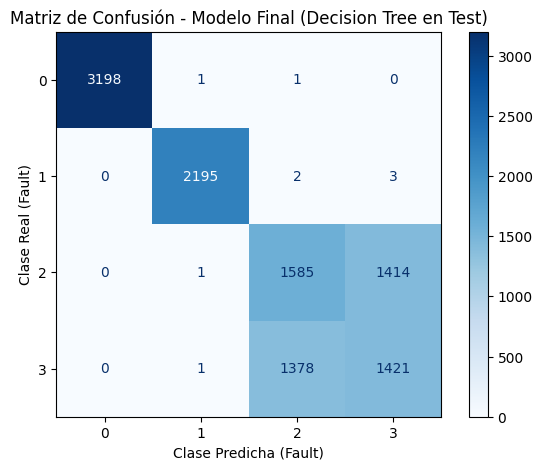

In [26]:
#import matplotlib.pyplot as plt
#import seaborn as sns
#from sklearn.pipeline import Pipeline
#from sklearn.preprocessing import StandardScaler
#from sklearn.tree import DecisionTreeClassifier
#from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

#Instanciar el modelo ganador elegido en la Sección 6
modelo_final = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', DecisionTreeClassifier(random_state=seed))
])

#Entrenar con TODO el conjunto de entrenamiento (X_train, y_train)
modelo_final.fit(X_train, y_train)

#Evaluar UNA SOLA VEZ sobre el conjunto de prueba (X_test)
y_pred_final = modelo_final.predict(X_test)

#Reportar métrica principal (F1-Macro) y desglose por clase
f1_final = f1_score(y_test, y_pred_final, average='macro')
print(f"=== Evaluación Final en Conjunto de Prueba (Caso a) ===")
print(f"F1-Macro Final (Métrica Principal): {f1_final:.4f}\n")
print("Reporte de Clasificación por Clase:")
print(classification_report(y_test, y_pred_final, digits=4))

#Generar y graficar la Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_final)

fig, ax = plt.subplots(figsize=(7, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1, 2, 3])
disp.plot(cmap='Blues', values_format='d', ax=ax)
ax.set_title('Matriz de Confusión - Modelo Final (Decision Tree en Test)')
ax.set_xlabel('Clase Predicha (Fault)')
ax.set_ylabel('Clase Real (Fault)')
plt.grid(False)
plt.show()

<br/>

**Generalización del modelo final:**

El modelo ganador (Árbol de Decisión) alcanzó un F1-Macro de 0.7583 y un Accuracy de 0.7499 sobre los $11,200$ registros del conjunto de prueba. Este puntaje coincide de forma consistente con el rendimiento estimado en validación cruzada (0.7562 ± 0.0035), demostrando estabilidad y ausencia de sobreajuste al conjunto de entrenamiento.   

* Desglose de aciertos y confusiones frecuentes (Matriz de Confusión):

  1. Separación casi perfecta en las clases 0 y 1: El modelo distingue con precisión prácticamente absoluta la operación normal (Fault = 0, con $3,198$ aciertos de $3,200$ y F1 = 0.9997) y la falla tipo 1 (Fault = 1, con $2,195$ aciertos de $2,200$ y F1 = 0.9982). En términos operativos, el riesgo de Falsos Negativos críticos hacia la clase sana (0) es prácticamente nulo ($0$ fallas reales clasificadas como motor sano).   
  2. Confusión concentrada exclusivamente entre las clases 2 y 3: Casi el $100\%$ de los errores del modelo ocurren como un intercambio mutuo entre estas dos fallas:   
  
      * De $3,000$ instancias reales de la clase 2, $1,585$ se clasificaron correctamente, pero $1,414$ fueron confundidas como clase 3 (F1 = 0.5313).   
      * De $2,800$ instancias reales de la clase 3, $1,421$ se acertaron y $1,378$ se confundieron como clase 2 (F1 = 0.5041).   
      
      
* Relación con el diagnóstico de la Sección 2:

  * Solapamiento entre clases: Este comportamiento confirma directamente el traslape diagnosticado en la Sección 2. Mientras que las clases 0 y 1 ocupan regiones bien diferenciadas en el espacio de los sensores, las fallas 2 y 3 comparten firmas de operación casi idénticas (alto solapamiento), haciendo que el clasificador se comporte cerca del azar ($\approx 50\%$) al intentar distinguir una de otra.   
  * Multicolinealidad e implicación: Dado que múltiples sensores físicos están fuertemente correlacionados (como AFR/Lambda/CO o RPM/Speed), las particiones ortogonales de un solo Árbol de Decisión no encuentran una frontera nítida entre las fallas 2 y 3. Como trabajo futuro, se recomendaría explorar modelos de ensamble (como Random Forest o Gradient Boosting) o ingeniería de características basada en tasas de cambio entre sensores para desacoplar ambas fallas.
<br/>

---



## Sección 8. Conclusiones y limitaciones

**Debe incluir:**

- Respuesta al problema planteado.
- Limitaciones concretas del trabajo.
- Si se usó solo validación cruzada (caso b): indicar que el resultado es algo optimista, porque la misma validación sirvió para elegir el modelo.

<br/>

**1. Respuesta al problema planteado**

- **Viabilidad del diagnóstico predictivo:** El modelo final basado en Árbol de Decisión (DecisionTreeClassifier) dentro de un Pipeline con estandarización resolvió de manera efectiva la detección general de anomalías del motor, alcanzando un F1-Macro de 0.7583 y un Accuracy de 0.7499 sobre el conjunto de prueba independiente (11,200 observaciones), superando ampliamente el rendimiento del modelo lineal de referencia (F1-Macro = 0.5857).   

- **Seguridad operativa frente al costo de los errores:** Desde la perspectiva del negocio y la seguridad mecánica planteada en la Sección 1, el modelo cumple con el objetivo crítico de evitar Falsos Negativos hacia el estado normal: distingue con precisión prácticamente perfecta la operación saludable (Fault = 0, F1 = 0.9997) y la falla tipo 1 (Fault = 1, F1 = 0.9982), sin clasificar ninguna falla real como un motor sano (0 falsos negativos en la columna 0 de la matriz de confusión).   

- **Validez de la metodología:** La estrecha concordancia entre el desempeño de validación cruzada (0.7562 ± 0.0035) y la evaluación única en el conjunto de prueba (0.7583) confirma que el flujo de trabajo (estratificación, aislamiento del conjunto de prueba bajo el Caso (a) y escalado dentro del Pipeline) evitó la fuga de datos (data leakage) y produjo una estimación realista de generalización.   
<br/>

**2. Limitaciones concretas del trabajo**

- **Incapacidad para discriminar entre las fallas 2 y 3:** La principal limitación del modelo actual radica en el fuerte solapamiento entre las fallas tipo 2 y 3, donde el clasificador confunde casi la mitad de los casos entre ambas (F1 = 0.5313 para la clase 2 y F1 = 0.5041 para la clase 3). Aunque el sistema alerta confiablemente que existe una falla (y no un motor sano), requiere intervención o diagnóstico adicional para precisar cuál de esas dos averías específicas ocurre.   

- **Ausencia de ajuste fino de hiperparámetros y modelos de ensamble:** Se evaluó un único Árbol de Decisión con parámetros por defecto, cuya estructura de particiones ortogonales resulta insuficiente para trazar fronteras complejas en regiones altamente solapadas. Explorar algoritmos de ensamble (como Random Forest o Gradient Boosting) y optimizar hiperparámetros (max_depth, min_samples_split, criterion) podría mejorar la separación entre las clases 2 y 3.

- **Naturaleza estática de las observaciones:** El conjunto de datos modela cada lectura instantánea de los 14 sensores de forma independiente, sin incorporar información temporal o secuencial (como derivadas, tasas de cambio o ventanas móviles de temperatura/presión), las cuales suelen ser determinantes en el diagnóstico mecánico real para diferenciar fallas con lecturas instantáneas similares.   

- **Falta de contexto físico sobre el origen de los datos:** Al tratarse de un dataset anonimizado en sus etiquetas de falla (0 a 3), no se dispone de información sobre si las mediciones provienen de un mismo motor bajo condiciones controladas de laboratorio o de distintos vehículos en operación real, lo que limita la certeza sobre su generalización fuera de este entorno de prueba.